# Data Cleansing

- saves `data/data_integrated.csv` from `data/data_desktop.csv` and `"data/data_web.csv`
  - Desktop: N=55 => N=53
  - Web: N=254 => N=229

## Setup

Import libraries.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Util

In [4]:
from scipy.stats import zscore

def outlier_by_zscore(dataframe, col, abs_z=3):
    z = zscore(dataframe[col].astype(float), nan_policy='omit')
    outliers = dataframe.loc[(abs(z) > abs_z), ["subj_id", col]].copy()
    outliers["z-score"] = z[(abs(z) > abs_z)]
    return outliers

def print_summary(data, name):
    print(f"{name}: mean = {data.mean():.2f}, std = {data.std():.2f} (min={data.min()} ~ max={data.max()})")
    print(f"{name}: {data.mean():.1f} ± {data.std():.1f}")

def plot_summary(plot, data, title, xlable=None, ylable=None, bins=10):
    plot.hist(data, bins=bins, edgecolor="black")
    if xlable is not None:
        plot.set_xlabel(xlable)
    else:
        plot.set_xlabel(title)
    if ylable is not None:
        plot.set_ylabel("Frequency")
    else:
        plot.set_ylabel(ylable)
    plot.set_title(title)

## Data

### Load Raw Data

In [5]:
df_desktop = pd.read_csv("data/data_desktop.csv", encoding="utf-8-sig")
df_desktop = df_desktop.drop(columns=["school_year"])
print(f"N={len(df_desktop)}")
df_desktop.head()

N=55


,subj_id,age,gender,BIS,BIS_motor,BIS_nonplanning,BIS_attentional,BIS_same_response,STAI,STAI_S,...,sideway_movements_toward_visible_crosswalk_safe_zone_cnt_mid_penalty_session2,sideway_movements_toward_visible_crosswalk_safe_zone_cnt_high_penalty_session2,sideway_movements_toward_visible_crosswalk_danger_zone_cnt_total_session2,sideway_movements_toward_visible_crosswalk_danger_zone_cnt_easy_session2,sideway_movements_toward_visible_crosswalk_danger_zone_cnt_hard_session2,sideway_movements_toward_visible_crosswalk_danger_zone_cnt_low_penalty_session2,sideway_movements_toward_visible_crosswalk_danger_zone_cnt_mid_penalty_session2,sideway_movements_toward_visible_crosswalk_danger_zone_cnt_high_penalty_session2,DDT_mean_log_k,CRA_mean_alpha
0,904,22,1,73,23,31,19,-1,87,44,...,77,91,21,3,18,4,3,14,-3.272599,0.347513
1,1000,32,2,61,18,22,21,-1,84,38,...,31,26,22,2,20,7,8,7,-6.330838,0.660547
2,1001,25,2,73,20,31,22,-1,77,38,...,4,3,14,2,12,2,6,6,-7.961866,0.612792
3,1002,21,2,63,22,22,19,-1,73,38,...,39,64,28,2,26,11,13,4,-1.564452,1.412119
4,1003,26,2,69,22,24,23,-1,86,40,...,24,13,46,2,44,13,16,17,-5.378190,0.668441


In [8]:
df_web = pd.read_csv("data/data_web.csv", encoding="utf-8-sig")
print(f"N={len(df_web)}")
df_web.head()

N=254


,subj_id,age,gender,BIS,BIS_motor,BIS_nonplanning,BIS_attentional,BIS_same_response,STAI,STAI_S,...,sideway_movements_toward_visible_crosswalk_safe_zone_cnt_hard_session2,sideway_movements_toward_visible_crosswalk_safe_zone_cnt_low_penalty_session2,sideway_movements_toward_visible_crosswalk_safe_zone_cnt_mid_penalty_session2,sideway_movements_toward_visible_crosswalk_safe_zone_cnt_high_penalty_session2,sideway_movements_toward_visible_crosswalk_danger_zone_cnt_total_session2,sideway_movements_toward_visible_crosswalk_danger_zone_cnt_easy_session2,sideway_movements_toward_visible_crosswalk_danger_zone_cnt_hard_session2,sideway_movements_toward_visible_crosswalk_danger_zone_cnt_low_penalty_session2,sideway_movements_toward_visible_crosswalk_danger_zone_cnt_mid_penalty_session2,sideway_movements_toward_visible_crosswalk_danger_zone_cnt_high_penalty_session2
0,663ff3e539df6ec6f060f875,28,1,83,30,33,20,-1,128,63,...,247,106,129,129,5,0,5,5,0,0
1,69b37d42378c672c56abb20b,41,1,83,27,31,25,-1,102,41,...,196,49,65,105,7,0,7,6,0,1
2,67f192e08cf17c568074969d,39,1,45,14,21,10,-1,61,29,...,239,98,107,103,9,2,7,0,6,3
3,6786abc3a98055356d70eb64,47,2,52,19,22,11,-1,85,42,...,164,83,77,98,6,0,6,4,0,2
4,69a9e5bf591680851043ed1c,29,2,70,26,28,16,-1,92,44,...,102,29,71,60,0,0,0,0,0,0


### Integrate into single dataframe

In [9]:
df_desktop["web"] = False
df_web["web"] = True
df = pd.concat([df_desktop, df_web], ignore_index=True)

for col in df.columns:
    if df[col].dtype == "object":
        vals = df[col].dropna().unique()
        if len(vals) > 0 and set(vals).issubset({True, False}):
            df[col] = df[col].astype("boolean")

print(f"N={len(df_desktop)}+{len(df_web)}={len(df)}")

N=55+254=309


## Crosswalk Task Performance Screening

- Desktop (N=2)
- Web (N=9)

### Minimum Average Score Screening

Desktop (N=55): mean = 911.33, std = 166.62 (min=443.29896907216494 ~ max=1254.2553191489362)
Desktop (N=55): 911.3 ± 166.6
Web (N=254): mean = 841.46, std = 214.44 (min=216.82692307692307 ~ max=1304.5045045045044)
Web (N=254): 841.5 ± 214.4


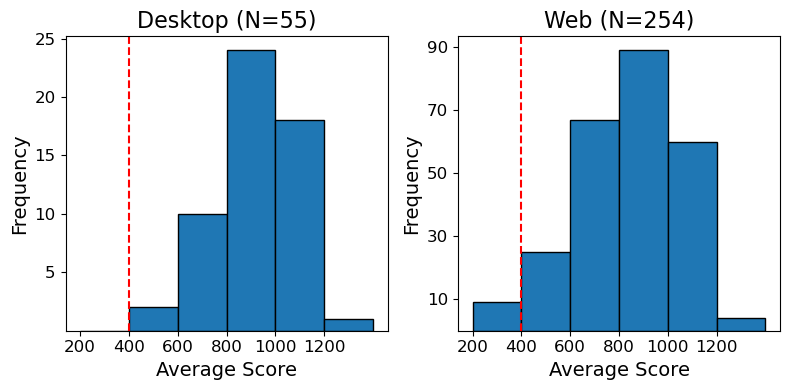

In [10]:
col = "average_score_full"
min_high_score_threshold = 400 # based on Desktop sample distribution

def plot_task_summary(
    plot,
    data,
    title,
    bins,
    title_fontsize=16,
    label_fontsize=14,
    tick_fontsize=12,
):
    plot.hist(data, bins=bins, edgecolor="black")
    plot.set_xlabel("Average Score", fontsize=label_fontsize)
    plot.set_ylabel("Frequency", fontsize=label_fontsize)
    plot.set_title(title, fontsize=title_fontsize)
    plot.tick_params(axis="both", labelsize=tick_fontsize)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for i in range(2):
    dataframe = [df_desktop, df_web][i]
    title = [f"Desktop (N={len(df_desktop)})", f"Web (N={len(df_web)})"][i]
    print_summary(dataframe[col], title)
    plot_task_summary(axes[i], dataframe[col], title, bins=np.arange(200, 1401, 200))
    axes[i].axvline(min_high_score_threshold, linestyle='--', color="red")
    axes[i].set_xticks(range(200, 1200+1, 200))

axes[0].set_yticks(range(5, 26, 5))
axes[1].set_yticks(range(10, 91, 20))

plt.tight_layout()
plt.show()

In [11]:
best_score_desktop_df = df_desktop[df_desktop["average_score_full"] < min_high_score_threshold]
min_average_score_desktop_subj_ids = list(best_score_desktop_df["subj_id"])
print(f"Desktop: N={len(min_average_score_desktop_subj_ids)}")
# print(min_average_score_desktop_subj_ids)

best_score_web_df = df_web[df_web["average_score_full"] < min_high_score_threshold]
min_average_score_web_subj_ids = list(best_score_web_df["subj_id"])
print(f"Web: N={len(min_average_score_web_subj_ids)}")
print(min_average_score_web_subj_ids)

Desktop: N=0
Web: N=9
['69c55b66d8ade7f9bd6109d6', '69bd9f66451b01fdf0b14f81', '69a909cc62a01823bc535039', '6647b26b402c0a3c5ab8b0cd', '5d9b7c7efaa2860364b16476', '662bf98a6f25e5ccdce46ebc', '676ed8014625d5ebd417b5f2', '69972cda9a2b697e924fe91b', '66541006a1dd56700858320a']


### Z-score screening: Average Score & Best Score

In [12]:
desktop_average_score_df = outlier_by_zscore(df_desktop, "average_score_full")
desktop_average_score_subj_ids = list(desktop_average_score_df["subj_id"])
print(f"N={len(desktop_average_score_subj_ids)}")

N=0


In [13]:
desktop_best_score_df = outlier_by_zscore(df_desktop, "best_score_full")
desktop_best_score_subj_ids = list(desktop_best_score_df["subj_id"])
print(f"N={len(desktop_best_score_subj_ids)}")
desktop_best_score_df

N=2


,subj_id,best_score_full,z-score
22,1022,1600,-3.731593
51,1051,1650,-3.191494


In [14]:
web_average_score_df = outlier_by_zscore(df_web, "average_score_full")
web_average_score_subj_ids = list(web_average_score_df["subj_id"])
print(f"N={len(web_average_score_subj_ids)}")

N=0


In [15]:
web_best_score_df = outlier_by_zscore(df_web, "best_score_full")
web_best_score_subj_ids = list(web_best_score_df["subj_id"])
print(f"N={len(web_best_score_subj_ids)}")

N=5


## Straightlining Screening

- Desktop (N=0)
- Web (N=11)

In [21]:
print("BIS_same_response:", len(df_web[df_web["BIS_same_response"] > 0]))
print("STAI_same_response:", len(df_web[df_web["STAI_same_response"] > 0]))
print("DOSPERT_same_response:", len(df_web[df_web["DOSPERT_same_response"] > 0]))
print("CES_D_same_response:", len(df_web[df_web["CES_D_same_response"] > 0]))
print("IGDS_same_response:", len(df_web[df_web["IGDS_same_response"] > 0]))
print("IAT_same_response:", len(df_web[df_web["IAT_same_response"] > 0]))
print("S_UPPS_same_response:", len(df_web[df_web["S_UPPS_same_response"] > 0]))

BIS_same_response: 0
STAI_same_response: 0
DOSPERT_same_response: 0
CES_D_same_response: 0
IGDS_same_response: 52
IAT_same_response: 11
S_UPPS_same_response: 0


In [22]:
print("IGDS_same_response:", len(df_web[df_web["IGDS_same_response"] == 1]))
print("IGDS_same_response:", len(df_web[df_web["IGDS_same_response"] > 1]))

IGDS_same_response: 51
IGDS_same_response: 1


In [23]:
print("IAT_not_applicable_cnt:", len(df_web[df_web["IAT_not_applicable_cnt"] > 0]))
print("IAT_same_response:", len(df_web[df_web["IAT_same_response"] > 0]))

IAT_not_applicable_cnt: 185
IAT_same_response: 11


In [24]:
straightlining_df_web = df_web[(df_web["IAT_same_response"] > 0)]
straightlining_df_web[[
    "subj_id",
    "age",
    "IAT_same_response",
    "IAT_not_applicable_cnt",
    "IGDS_same_response",
]]

,subj_id,age,IAT_same_response,IAT_not_applicable_cnt,IGDS_same_response
26,5a8b1ee2000dab00018cc7cd,37,2,0,-1
33,66ecded667f721bca7e5609d,33,2,0,1
54,67d9ef30fe8af2858e8dbbd3,52,3,0,2
62,6143af8721d1445864c4f6c8,53,1,20,1
64,66c019586569ea36287bd523,42,2,0,1
93,670b016fcdbd02704561c953,21,2,0,1
102,59ffb939517dfb00013dadda,38,6,0,-1
142,67673cda94b4d0cf1a6a7382,58,2,0,1
176,697df9aa934d8b9de8f2afe9,29,4,0,-1
198,698e3769fd8fd99a4839dd03,45,2,0,1


In [25]:
straightlining_subj_ids = list(straightlining_df_web["subj_id"])
print(len(straightlining_subj_ids))
print(straightlining_subj_ids)

11
['5a8b1ee2000dab00018cc7cd', '66ecded667f721bca7e5609d', '67d9ef30fe8af2858e8dbbd3', '6143af8721d1445864c4f6c8', '66c019586569ea36287bd523', '670b016fcdbd02704561c953', '59ffb939517dfb00013dadda', '67673cda94b4d0cf1a6a7382', '697df9aa934d8b9de8f2afe9', '698e3769fd8fd99a4839dd03', '603006ea5f6c24dfc908f835']


## AIRL Training Result Screening

- Desktop (N=0)
- Web (N=8)

In [26]:
bad_airl_model_subj_ids = [
    "69c553153fe38731aa30e607", # trained until 30000 but failed # no sideways movement at all
    "59ffb939517dfb00013dadda", # training completely failed until 30000
    "69bd9f66451b01fdf0b14f81", # training failed until 30000 # noop for over 10 seconds episode detected - 1 out of 128 episodes [2029]
    "614d465852620924f85603c8", # training failed until 30000

    "667d08e12ac1bcbdd829a936", # almost no left/right movements # action 2: accuracy=0.2381 (count=42) # action 3: accuracy=0.0000 (count=1) # action 4: accuracy=0.0000 (count=3)
    "69a351d666e8b077b755f930", # accuracy=0.0000 for down/left/right actions
    "69d06e97acec084e8e7ce173", # accuracy=0.0000 for 2 actions # action 2: accuracy=0.0000 (count=13) # action 3: accuracy=0.0000 (count=50) # action 4: accuracy=0.2414 (count=58)
    "69c132b7ff339dc396efb34f", # accuracy=0.0000 for 2 actions # action 3: accuracy=0.0000 (count=21) # action 4: accuracy=0.0000 (count=18)
]
print(len(bad_airl_model_subj_ids))

8


## Cleanse and save

In [ ]:
cleansed_df = df.copy()
cleansed_df = cleansed_df[~cleansed_df["subj_id"].isin(min_average_score_web_subj_ids)]
cleansed_df = cleansed_df[~cleansed_df["subj_id"].isin(desktop_best_score_subj_ids)]
cleansed_df = cleansed_df[~cleansed_df["subj_id"].isin(list(straightlining_df_web["subj_id"]))]
cleansed_df = cleansed_df[~cleansed_df["subj_id"].isin(bad_airl_model_subj_ids)]

print()
print(f"Desktop: N={len(df_desktop)} => N={len(cleansed_df[cleansed_df['web'] == False])}")
print(f"Web: N={len(df_web)} => N={len(cleansed_df[cleansed_df['web'] == True])}")

N=254 => N=229
N=55 => N=53


In [34]:
print(f"N={len(cleansed_df[cleansed_df['web'] == False])}+{len(cleansed_df[cleansed_df['web'] == True])}={len(cleansed_df)}")
cleansed_df.to_csv("data/data_integrated.csv", index=False)

N=53+229=282
